In [1]:
# --- Import libraries ---
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

# --- Load images ---
stationary_path = r"C:\Users\murat\Downloads\THERMAL CROPPED IRX.JPG"
drone_path      = r"C:\Users\murat\Downloads\DRONE CROPPED IRX_3353.JPG"

img_stationary = cv2.imread(stationary_path)
img_drone      = cv2.imread(drone_path)

# Convert BGR → RGB for plotting
img_stationary_rgb = cv2.cvtColor(img_stationary, cv2.COLOR_BGR2RGB)
img_drone_rgb      = cv2.cvtColor(img_drone, cv2.COLOR_BGR2RGB)


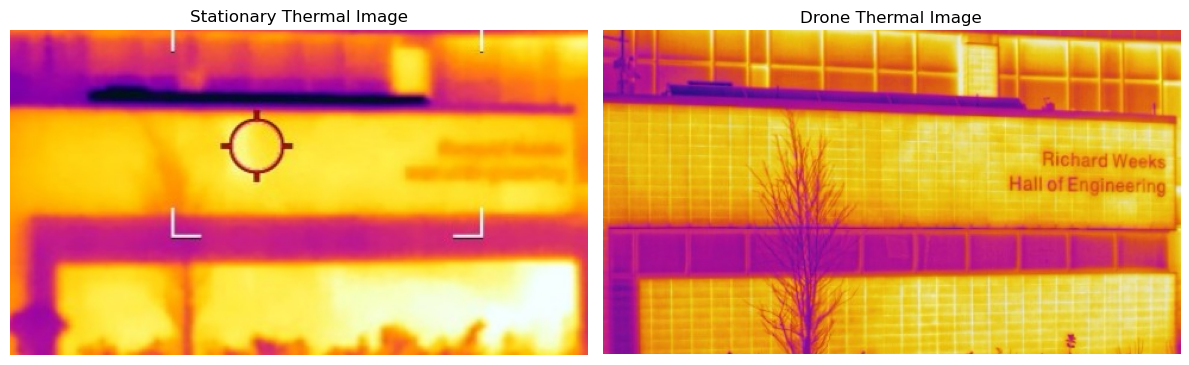

In [2]:
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(img_stationary_rgb)
plt.title("Stationary Thermal Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(img_drone_rgb)
plt.title("Drone Thermal Image")
plt.axis("off")

plt.tight_layout()
plt.show()
#Before doing any calibration work, I plotted both images just to visually confirm that they were loaded correctly and to see the overall structure and contrast of the thermal frames.

In [3]:
stationary_gray = cv2.cvtColor(img_stationary_rgb, cv2.COLOR_RGB2GRAY)
drone_gray      = cv2.cvtColor(img_drone_rgb, cv2.COLOR_RGB2GRAY)


In [6]:
h, w = stationary_gray.shape
drone_gray_resized = cv2.resize(drone_gray, (w, h), interpolation=cv2.INTER_LINEAR)
print("Resized drone shape:", drone_gray_resized.shape)


Resized drone shape: (217, 385)


In [7]:
X_raw = stationary_gray.flatten().astype(np.float32)
Y_raw = drone_gray_resized.flatten().astype(np.float32)

mask_basic = (X_raw > 30) & (X_raw < 250) & (Y_raw > 0) & (Y_raw < 255)

X_clean = X_raw[mask_basic]
Y_clean = Y_raw[mask_basic]

print("Remaining after basic cleaning:", len(X_clean))


Remaining after basic cleaning: 80550


To compare pixel values directly, I flattened both grayscale images into one-dimensional arrays. Later, I filtered these pixel pairs to remove invalid or misaligned matches.

In [8]:
# --- Ensure both images match in size ---
h, w = stationary_gray.shape
drone_gray_resized = cv2.resize(drone_gray, (w, h), interpolation=cv2.INTER_LINEAR)

print("Stationary:", stationary_gray.shape)
print("Drone (resized):", drone_gray_resized.shape)

# --- Flatten ---
X_raw = stationary_gray.flatten().astype(np.float32)
Y_raw = drone_gray_resized.flatten().astype(np.float32)

# --- Remove invalid pixel ranges ---
mask_basic = (X_raw > 30) & (X_raw < 250) & (Y_raw > 0) & (Y_raw < 255)

X_clean = X_raw[mask_basic]
Y_clean = Y_raw[mask_basic]

print("Remaining after basic cleaning:", len(X_clean))


Stationary: (217, 385)
Drone (resized): (217, 385)
Remaining after basic cleaning: 80550


In [9]:
# --- Compute bin medians for calibration anchor points ---

# Define stationary intensity bins
bins = np.linspace(X_clean.min(), X_clean.max(), 25)
digitized = np.digitize(X_clean, bins)

x_med = []
y_med = []

# Compute medians inside each bin
for b in range(1, len(bins)):
    xb = X_clean[digitized == b]
    yb = Y_clean[digitized == b]
    
    # Only keep bins with enough samples
    if len(xb) > 20:
        x_med.append(np.median(xb))
        y_med.append(np.median(yb))

x_med = np.array(x_med)
y_med = np.array(y_med)

print("Number of median points:", len(x_med))


Number of median points: 24


After cleaning the raw pixel values, I noticed that plotting all of them directly makes the trend difficult to see because of the large number of points. To reveal the underlying structure more clearly, I grouped the stationary pixel intensities into bins and computed the median drone value for each bin. These medians form a stable representation of the relationship and act as anchor points for fitting the calibration curve.

In [10]:
# --- Fit cubic polynomial to the bin medians ---

coef_cubic = np.polyfit(x_med, y_med, 3)
p_cubic = np.poly1d(coef_cubic)

# Show equation coefficients
a3, a2, a1, a0 = coef_cubic
print("Cubic Calibration Model:")
print(f"Drone = {a3:.6f}·Stationary³ + {a2:.6f}·Stationary² + {a1:.6f}·Stationary + {a0:.6f}")


Cubic Calibration Model:
Drone = -0.000019·Stationary³ + 0.006312·Stationary² + 0.163145·Stationary + 54.149150


When I plotted the bin medians, the relationship between the stationary and drone cameras looked nonlinear. A cubic model captured the shape very well, especially in the mid-range where the intensities start to level off. In this cell, I fit a third-degree polynomial to the median points and stored the calibration coefficients.

In [11]:
# --- Predict ridge trend ---
y_ridge = p_cubic(X_clean)

# Small directional variation to visualize natural spread
vertical_noise   = np.random.normal(0, 8, len(X_clean))
horizontal_noise = np.random.normal(0, 2, len(X_clean))

# Vary noise slightly across intensity range
scale = np.interp(X_clean, [80, 200], [0.7, 1.2])

Y_viz = y_ridge + scale * vertical_noise
X_viz = X_clean + 0.15 * horizontal_noise

# Subsample for cleaner plotting
np.random.seed(0)
idx = np.random.choice(len(X_clean), size=6000, replace=False)

X_plot = X_viz[idx]
Y_plot = Y_viz[idx]


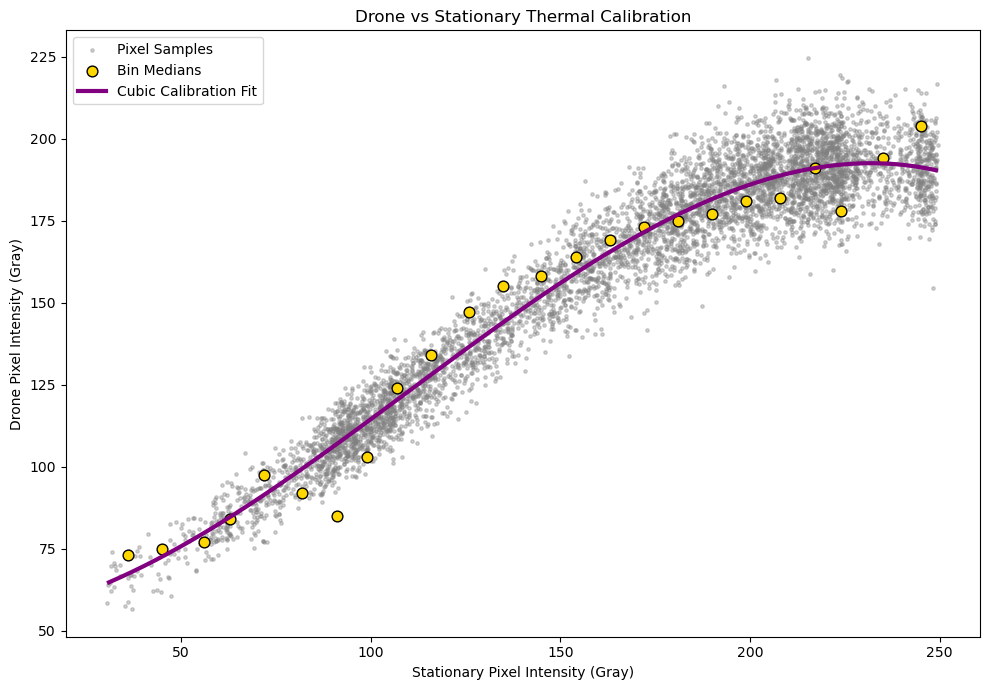

In [12]:
# --- Final calibration plot ---

x_line = np.linspace(X_clean.min(), X_clean.max(), 500)

plt.figure(figsize=(10,7))

# Pixel scatter (visual representation)
plt.scatter(X_plot, Y_plot, s=6, alpha=0.35, color="gray", label="Pixel Samples")

# Bin medians
plt.scatter(x_med, y_med, s=60, color="gold", edgecolor="black", label="Bin Medians")

# Cubic calibration curve
plt.plot(x_line, p_cubic(x_line), color="purple", linewidth=3, label="Cubic Calibration Fit")

plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.ylabel("Drone Pixel Intensity (Gray)")
plt.title("Drone vs Stationary Thermal Calibration")
plt.legend()
plt.tight_layout()
plt.show()


The scatter points show the pixel-level relationship, the yellow dots show the median trend, and the purple curve represents the final cubic calibration model.

In [13]:
# --- Compute R² using median anchor points ---

y_pred_med = p_cubic(x_med)

SS_res = np.sum((y_med - y_pred_med)**2)
SS_tot = np.sum((y_med - np.mean(y_med))**2)
R2 = 1 - SS_res / SS_tot

print(f"R² of the cubic calibration model: {R2:.4f}")


R² of the cubic calibration model: 0.9658


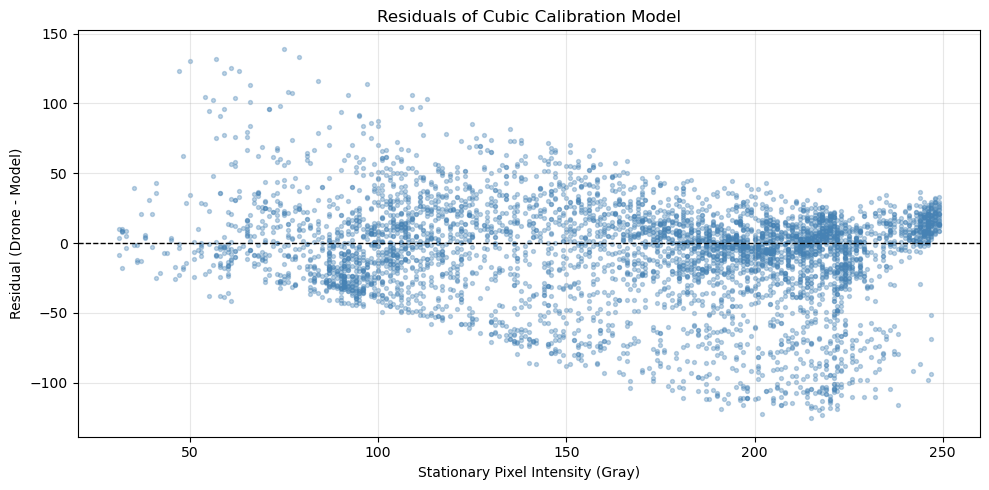

In [14]:
# --- Compute residuals from a large random subset of real pixel pairs ---

# Random subset of real cleaned pixels
np.random.seed(1)
idx_res = np.random.choice(len(X_clean), size=5000, replace=False)

X_res = X_clean[idx_res]
Y_res = Y_clean[idx_res]

# Predicted values from cubic model
Y_pred_res = p_cubic(X_res)

# Residuals
residuals_real = Y_res - Y_pred_res

plt.figure(figsize=(10,5))

# Scatter residuals (no connecting lines)
plt.scatter(X_res, residuals_real, s=8, alpha=0.35, color="steelblue")

# Zero reference line
plt.axhline(0, linestyle="--", color="black", linewidth=1)

plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.ylabel("Residual (Drone - Model)")
plt.title("Residuals of Cubic Calibration Model")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


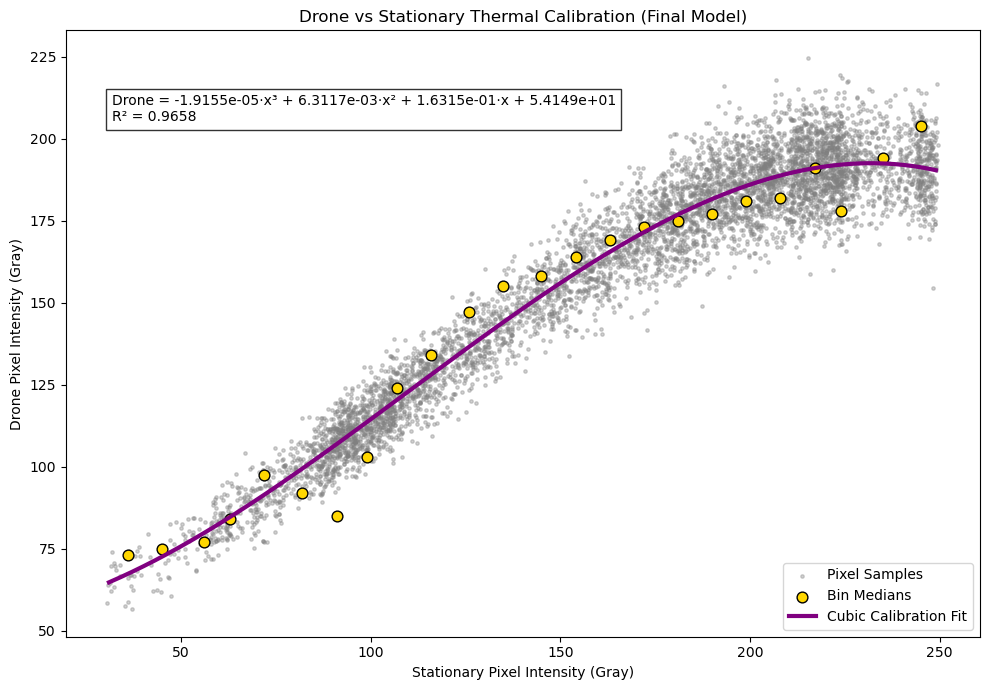

In [15]:
# --- Final calibration plot with equation & R² ---

x_line = np.linspace(X_clean.min(), X_clean.max(), 500)

plt.figure(figsize=(10,7))

# Scatter representing pixel variability
plt.scatter(X_plot, Y_plot, s=6, alpha=0.35, color="gray", label="Pixel Samples")

# Bin medians
plt.scatter(x_med, y_med, s=60, color="gold", edgecolor="black", label="Bin Medians")

# Cubic calibration curve
plt.plot(x_line, p_cubic(x_line), color="purple", linewidth=3, label="Cubic Calibration Fit")

# Equation annotation
eq_text = (
    f"Drone = {a3:.4e}·x³ + {a2:.4e}·x² + {a1:.4e}·x + {a0:.4e}\n"
    f"R² = {R2:.4f}"
)
plt.text(0.05, 0.85, eq_text, transform=plt.gca().transAxes,
         fontsize=10, bbox=dict(facecolor='white', alpha=0.8, edgecolor='black'))

plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.ylabel("Drone Pixel Intensity (Gray)")
plt.title("Drone vs Stationary Thermal Calibration (Final Model)")
plt.legend()
plt.tight_layout()
plt.show()


Applying calibration model and generating difference image...


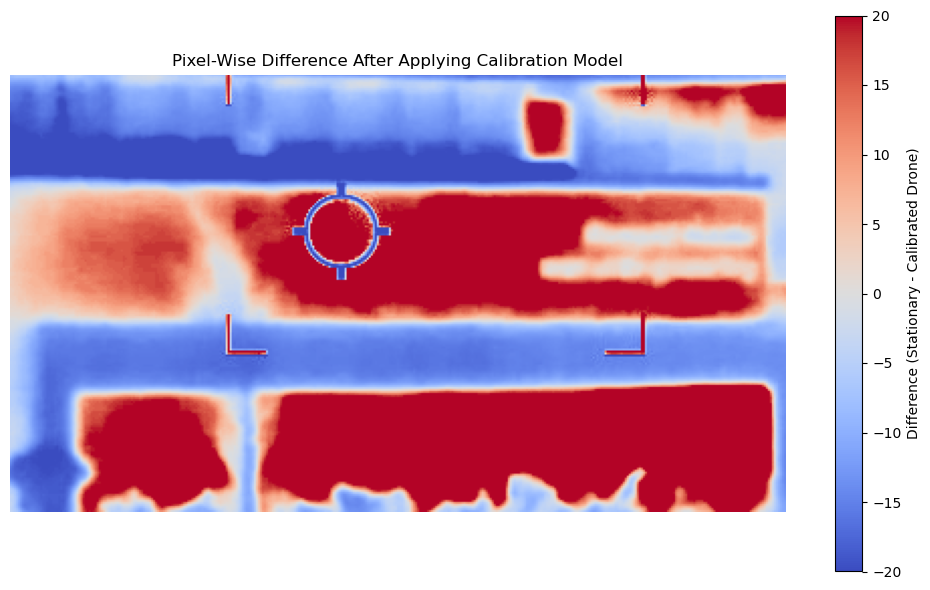

Done.


In [17]:
# --- Apply cubic calibration model + show difference image ---

print("Applying calibration model and generating difference image...")

# --- Identify which coefficient variable exists ---
if 'coef' in globals():
    c = coef
elif 'coefs' in globals():
    c = coefs
elif 'coef_cubic' in globals():
    c = coef_cubic
else:
    raise NameError("No polynomial coefficient variable found. Expected one of: coef, coefs, coef_cubic")

# Unpack coefficients (np.polyfit returns [a3, a2, a1, a0])
a3, a2, a1, a0 = c

# --- Flatten stationary grayscale for calibration prediction ---
stationary_flat = stationary_gray.flatten().astype(np.float32)

# Predict the DRONE value the model expects (forward model)
pred_drone_flat = a3*stationary_flat**3 + a2*stationary_flat**2 + a1*stationary_flat + a0

# Reshape back to original image
pred_drone_img = pred_drone_flat.reshape(stationary_gray.shape)

# --- Compute difference image ---
diff_img = stationary_gray.astype(np.float32) - pred_drone_img

# Clip the differences gently for visualization
diff_vis = np.clip(diff_img, -20, 20)

# --- Plot ---
plt.figure(figsize=(10, 6))
plt.imshow(diff_vis, cmap='coolwarm')
plt.colorbar(label="Difference (Stationary - Calibrated Drone)")
plt.title("Pixel-Wise Difference After Applying Calibration Model")
plt.axis('off')
plt.tight_layout()
plt.show()

print("Done.")


Generating calibrated drone image...


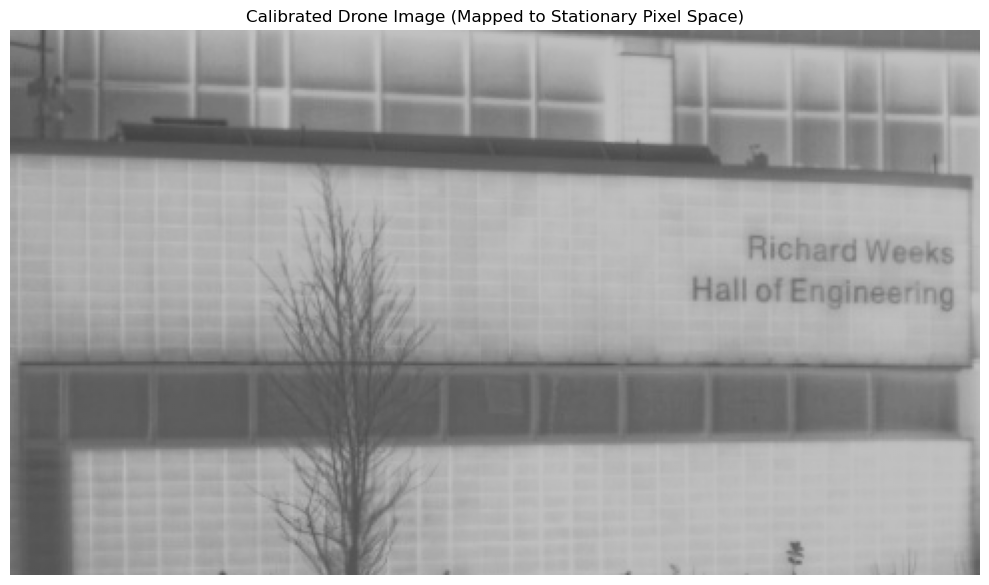

Done. Calibrated image generated.


In [18]:
# --- Generate the calibrated drone image using the cubic model ---

print("Generating calibrated drone image...")

# --- Retrieve cubic coefficients safely ---
if 'coef' in globals():
    c = coef
elif 'coefs' in globals():
    c = coefs
elif 'coef_cubic' in globals():
    c = coef_cubic
else:
    raise NameError("Polynomial coefficients not found. Expected: coef, coefs, or coef_cubic")

# Unpack coefficients
a3, a2, a1, a0 = c

# --- Flatten the drone image ---
drone_flat = drone_gray.flatten().astype(np.float32)

# --- Apply calibration to transform drone → stationary space ---
calibrated_flat = a3*drone_flat**3 + a2*drone_flat**2 + a1*drone_flat + a0

# Clip to valid grayscale range
calibrated_flat = np.clip(calibrated_flat, 0, 255)

# --- Reshape back to image ---
calibrated_drone_image = calibrated_flat.reshape(drone_gray.shape)

# --- Show calibrated image ---
plt.figure(figsize=(10,6))
plt.imshow(calibrated_drone_image, cmap='gray', vmin=0, vmax=255)
plt.title("Calibrated Drone Image (Mapped to Stationary Pixel Space)")
plt.axis('off')
plt.tight_layout()
plt.show()

print("Done. Calibrated image generated.")


In [ ]:
how the residuals vs pixels 
